In [3]:
import saikit_learn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_original = pd.read_csv("../../../data/processed/superconductivity_duplicated.csv")
df = df_original.copy()
df.head(5)

,number_of_elements,mean_atomic_mass,wtd_mean_atomic_mass,gmean_atomic_mass,wtd_gmean_atomic_mass,entropy_atomic_mass,wtd_entropy_atomic_mass,range_atomic_mass,wtd_range_atomic_mass,std_atomic_mass,...,wtd_mean_Valence,gmean_Valence,wtd_gmean_Valence,entropy_Valence,wtd_entropy_Valence,range_Valence,wtd_range_Valence,std_Valence,wtd_std_Valence,critical_temp
0,4,88.944468,57.862692,66.361592,36.116612,1.181795,1.062396,122.90607,31.794921,51.968828,...,2.257143,2.213364,2.219783,1.368922,1.066221,1,1.085714,0.433013,0.437059,29.0
1,5,92.729214,58.518416,73.132787,36.396602,1.449309,1.057755,122.90607,36.161939,47.094633,...,2.257143,1.888175,2.210679,1.557113,1.047221,2,1.128571,0.632456,0.468606,26.0
2,4,88.944468,57.885242,66.361592,36.122509,1.181795,0.975980,122.90607,35.741099,51.968828,...,2.271429,2.213364,2.232679,1.368922,1.029175,1,1.114286,0.433013,0.444697,19.0
3,4,88.944468,57.873967,66.361592,36.119560,1.181795,1.022291,122.90607,33.768010,51.968828,...,2.264286,2.213364,2.226222,1.368922,1.048834,1,1.100000,0.433013,0.440952,22.0
4,4,88.944468,57.840143,66.361592,36.110716,1.181795,1.129224,122.90607,27.848743,51.968828,...,2.242857,2.213364,2.206963,1.368922,1.096052,1,1.057143,0.433013,0.428809,23.0


In [ ]:
from saikit_learn.regression import OLS, Ridge, Lasso, PolReg
from saikit_learn.decision_tree import DecisionTreeRegressor
from saikit_learn.neural_network import MLPRegressor
from saikit_learn.preprocessing import StandardScaler, Pipeline
from saikit_learn.regression_metrics import MSE, RMSE, MAE, RSS, R2, R2_ajusted

In [6]:
df_treino = pd.read_csv("../../../data/processed/treino_regressao.csv")
df_teste = pd.read_csv("../../../data/processed/teste_regressao.csv")

print("Treinamento:", df_treino.shape)
print("Teste:", df_teste.shape)

Treinamento: (14838, 82)
Teste: (6359, 82)


In [ ]:
#Separando para ter os conjuntos de treino, validação e teste
df_ajuste = df_treino.sample(frac=0.8, random_state=42)
df_valid = df_treino.drop(df_ajuste.index)

print("Ajuste:", df_ajuste.shape)
print("Validação:", df_valid.shape)

Ajuste: (11870, 82)
Validação: (2968, 82)


In [ ]:
# Correlação Pearson entre as variáveis com a variável alvo - DS 
correlacoes = df_ajuste.corr()["critical_temp"].drop("critical_temp")
correlacoes.abs().sort_values(ascending=False).head(10)

wtd_std_ThermalConductivity    0.715276
range_ThermalConductivity      0.680639
range_atomic_radius            0.652881
std_ThermalConductivity        0.645879
wtd_mean_Valence               0.631212
wtd_entropy_atomic_mass        0.620912
wtd_gmean_Valence              0.614361
mean_Valence                   0.601164
wtd_std_atomic_radius          0.600847
range_fie                      0.600627
Name: critical_temp, dtype: float64

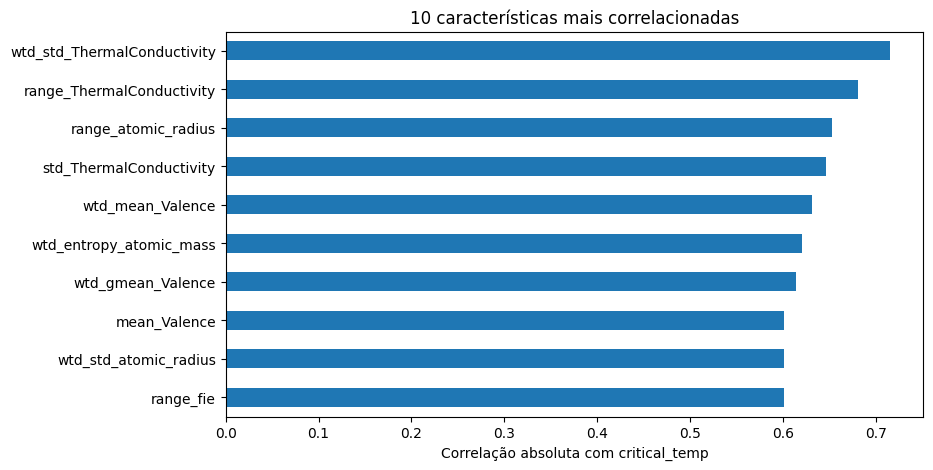

In [ ]:
correlacoes.abs().sort_values(ascending=False).head(10).sort_values().plot(kind="barh",figsize=(9, 5))

plt.xlabel("Correlação absoluta com critical_temp")
plt.title("10 características mais correlacionadas")
plt.show()

In [ ]:
#Conversão numpy - formato da biblioteca
X_train = df_ajuste.drop(columns=["critical_temp"]).to_numpy()
y_train = df_ajuste["critical_temp"].to_numpy()

X_valid = df_valid.drop(columns=["critical_temp"]).to_numpy()
y_valid = df_valid["critical_temp"].to_numpy()

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_valid:", X_valid.shape)
print("y_valid:", y_valid.shape)

X_train: (11870, 81)
y_train: (11870,)
X_valid: (2968, 81)
y_valid: (2968,)


In [ ]:
# Precisamos guardar o scaler para aplicar na validação a mesma padronização aprendida no treino para evitando vazamento de dados
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)

In [ ]:
#BASELINE para comparação dos modelos - média direta das temperaturas críticas do conjunto de treino

media_treino = y_train.mean()
y_pred_baseline = np.full(len(y_valid), media_treino)
print("MSE:", MSE(y_valid, y_pred_baseline))
print("RMSE:", RMSE(y_valid, y_pred_baseline))
print("MAE:", MAE(y_valid, y_pred_baseline))
print("R²:", R2(y_valid, y_pred_baseline))

MSE: 1176.694120105377
RMSE: 34.302975382689134
MAE: 29.470435675333864
R²: -3.551079109564981e-05


### OLS - Primeiro Modelo

In [16]:
modelo_ols = OLS()
modelo_ols.fit(X_train_scaled, y_train)
y_pred_ols = modelo_ols.predict(X_valid_scaled)
print("MSE:", MSE(y_valid, y_pred_ols))
print("RMSE:", RMSE(y_valid, y_pred_ols))
print("MAE:", MAE(y_valid, y_pred_ols))
print("R²:", R2(y_valid, y_pred_ols))

MSE: 318.78210833961464
RMSE: 17.854470262083236
MAE: 13.40866192411901
R²: 0.7290770616615982


In [18]:
#Tabela de compraração dos resultados dos modelos para compararmos
resultados = pd.DataFrame({
    "Modelo": ["Baseline", "OLS"],
    "MSE": [MSE(y_valid, y_pred_baseline),MSE(y_valid, y_pred_ols)],
    "RMSE": [RMSE(y_valid, y_pred_baseline),RMSE(y_valid, y_pred_ols)],
    "MAE": [MAE(y_valid, y_pred_baseline),MAE(y_valid, y_pred_ols)],
    "R2": [R2(y_valid, y_pred_baseline),R2(y_valid, y_pred_ols)]})

resultados

,Modelo,MSE,RMSE,MAE,R2
0,Baseline,1176.694120,34.302975,29.470436,-0.000036
1,OLS,318.782108,17.854470,13.408662,0.729077


In [ ]:
# De cara verificamos um desempenho bem melhor do OLS, em comparação com o baseline. Ainda sim, pelo R2 vemos que temos espaço de melhoria, 
# o proximo passo é tentar melhorá-lo com regularização, para isso vamos testar o Ridge e o Lasso.

### Ridge

In [ ]:
#testar diferentes penalizações ridge 
lambdas_ridge = [0.1, 1, 10, 100, 1000]
resultados_ridge = []

for lmbd in lambdas_ridge:
    modelo = Ridge(lmbd=lmbd)
    modelo.fit(X_train_scaled, y_train)
    previsoes = modelo.predict(X_valid_scaled)
    resultados_ridge.append([lmbd,RMSE(y_valid, previsoes),MAE(y_valid, previsoes),R2(y_valid, previsoes)])

tabela_ridge = pd.DataFrame(resultados_ridge,columns=["Lambda", "RMSE", "MAE", "R2"])

tabela_ridge.sort_values("RMSE")

,Lambda,RMSE,MAE,R2
0,0.1,17.852273,13.405925,0.729144
1,1.0,17.859032,13.416301,0.728939
2,10.0,17.932614,13.502233,0.726700
3,100.0,18.314938,13.886649,0.714923
4,1000.0,19.200200,14.788959,0.686698


In [22]:
# escolher melhor lambda para o ridge

melhor_lambda_ridge = tabela_ridge.loc[tabela_ridge["RMSE"].idxmin(), "Lambda"]

modelo_ridge = Ridge(lmbd=melhor_lambda_ridge)
modelo_ridge.fit(X_train_scaled, y_train)
y_pred_ridge = modelo_ridge.predict(X_valid_scaled)
print("Melhor lambda:", melhor_lambda_ridge)
print("RMSE:", RMSE(y_valid, y_pred_ridge))
print("R2:", R2(y_valid, y_pred_ridge))

Melhor lambda: 0.1
RMSE: 17.852273117451446
R2: 0.729143736308916


### Lasso


In [ ]:
# mesmo padrão do Riege
lambdas_lasso = [0.1, 1, 5]
resultados_lasso = []

for lmbd in lambdas_lasso:
    modelo = Lasso(lmbd=lmbd)
    modelo.fit(X_train_scaled, y_train)
    previsoes = modelo.predict(X_valid_scaled)

    resultados_lasso.append([lmbd,RMSE(y_valid, previsoes),MAE(y_valid, previsoes),R2(y_valid, previsoes)])

tabela_lasso = pd.DataFrame(resultados_lasso,columns=["Lambda", "RMSE", "MAE", "R2"])

tabela_lasso.sort_values("RMSE")

,Lambda,RMSE,MAE,R2
0,0.1,18.674840,14.210691,0.703609
1,1.0,20.430796,15.891247,0.645250
2,5.0,22.903725,17.853007,0.554175


In [25]:
# escolher melhjor lambda para o lasso
melhor_lambda_lasso = tabela_lasso.loc[tabela_lasso["RMSE"].idxmin(), "Lambda"]

modelo_lasso = Lasso(lmbd=melhor_lambda_lasso)
modelo_lasso.fit(X_train_scaled, y_train)
y_pred_lasso = modelo_lasso.predict(X_valid_scaled)
print("Melhor lambda:", melhor_lambda_lasso)
print("RMSE:", RMSE(y_valid, y_pred_lasso))
print("R2:", R2(y_valid, y_pred_lasso))

Melhor lambda: 0.1
RMSE: 18.674840475886707
R2: 0.7036085714908255


In [26]:
# Atualizando a tabela de comparaçãocom os resultados do Ridge e Lasso

resultados.loc[len(resultados)] = [
    "Ridge",MSE(y_valid, y_pred_ridge),RMSE(y_valid, y_pred_ridge),MAE(y_valid, y_pred_ridge),R2(y_valid, y_pred_ridge)]
resultados.loc[len(resultados)] = [ "Lasso",MSE(y_valid, y_pred_lasso),RMSE(y_valid, y_pred_lasso),MAE(y_valid, y_pred_lasso),
                                   R2(y_valid, y_pred_lasso)]
resultados.sort_values("RMSE")

,Modelo,MSE,RMSE,MAE,R2
2,Ridge,318.703655,17.852273,13.405925,0.729144
1,OLS,318.782108,17.854470,13.408662,0.729077
3,Lasso,348.749667,18.674840,14.210691,0.703609
0,Baseline,1176.694120,34.302975,29.470436,-0.000036


O riedge apresentou o melhor desempenho geral, com RMSE de 17 e R2 de 0,71. Apesar de ter sido quase o mesmo que o OLS. Por outro lado, o Lasso apresentou piora. Por fim, os tres modelos, até o momento, já superam o Baseline. 

### Arvore de Decisão

### Redes Neurais